In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

In [5]:
df = pd.read_csv("DataCoSupplyChainDataset.csv", encoding='latin1')

In [8]:
pd.set_option('display.max_columns', None)

In [9]:
df.head(5)

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Fname,Customer Id,Customer Lname,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,Cally,20755,Holloway,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,Irene,19492,Luna,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,Gillian,19491,Maldonado,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,Tana,19490,Tate,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,Orli,19489,Hendricks,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [10]:
# create copy for data cleaning and preprossing
df_data = df.copy()

In [11]:
df_data.head(2)

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Fname,Customer Id,Customer Lname,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,Cally,20755,Holloway,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,Irene,19492,Luna,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,Smart watch,327.75,0,1/18/2018 12:27,Standard Class


In [13]:
df_data.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Fname', 'Customer Id', 'Customer Lname',
       'Customer Segment', 'Customer State', 'Customer Street',
       'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude',
       'Longitude', 'Market', 'Order City', 'Order Country',
       'Order Customer Id', 'order date (DateOrders)', 'Order Id',
       'Order Item Cardprod Id', 'Order Item Discount',
       'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price',
       'Order Item Profit Ratio', 'Order Item Quantity', 'Sales',
       'Order Item Total', 'Order Profit Per Order', 'Order Region',
       'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id',
       'Product Category Id', 'Product Name', 'Product Price',
       'Product Status',

In [15]:
df_data.shape

(180519, 49)

In [16]:
df_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 49 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Fname                 180519 non-null  object 
 12  Customer Id                   

In [ ]:
# That's means we have a columns that have coomon data 
df_data['Order Customer Id'].isin(df_data['Customer Id']).all()

np.True_

In [ ]:
# Our Dataset have no duplicate rows.
df_data.duplicated().sum()

np.int64(0)

In [25]:
df_data.isna().sum()

Type                                  0
Days for shipping (real)              0
Days for shipment (scheduled)         0
Benefit per order                     0
Sales per customer                    0
Delivery Status                       0
Late_delivery_risk                    0
Category Id                           0
Category Name                         0
Customer City                         0
Customer Country                      0
Customer Fname                        0
Customer Id                           0
Customer Lname                        8
Customer Segment                      0
Customer State                        0
Customer Street                       0
Customer Zipcode                      3
Department Id                         0
Department Name                       0
Latitude                              0
Longitude                             0
Market                                0
Order City                            0
Order Country                         0


# We have 3 columns that have null values 
# Lname have 8 null values but it doesn't have any effect on our analysis
# Customer Zipcode have 3 null values but it doesn't have any effect on our analysis
# Order Zipcode have 155679 null values same it doesn't effect on our analysis 

In [26]:
# Let's remove the columns that have same data and also remove the columns that is irrelavent and have more then 50% of missing values.

columns_to_drop = ['Benefit per order','Sales per customer','Product Category Id','Order Customer Id','Order Item Cardprod Id','Order Item Product Price','Order Zipcode','Customer Zipcode']
df_data.drop(columns = columns_to_drop, inplace = True)

In [35]:
df_data.drop(columns = ['Product Status'], inplace = True)

In [44]:
df_data.shape

(180519, 40)

# Make Standardized Data

In [46]:
df_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 40 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Delivery Status                180519 non-null  object 
 4   Late_delivery_risk             180519 non-null  int64  
 5   Category Id                    180519 non-null  int64  
 6   Category Name                  180519 non-null  object 
 7   Customer City                  180519 non-null  object 
 8   Customer Country               180519 non-null  object 
 9   Customer Fname                 180519 non-null  object 
 10  Customer Id                    180519 non-null  int64  
 11  Customer Lname                 180511 non-null  object 
 12  Customer Segment              

In [ ]:
cols = ['order date (DateOrders)','shipping date (DateOrders)']

for col in cols:
    df_data[col] = pd.to_datetime(df_data[col])

In [50]:
# Check datatype change or not
df_data[['order date (DateOrders)','shipping date (DateOrders)']].dtypes

order date (DateOrders)       datetime64[ns]
shipping date (DateOrders)    datetime64[ns]
dtype: object

In [ ]:
# check if there is any missing values in the order date and shipping date columns
df_data[['order date (DateOrders)','shipping date (DateOrders)']].isna().sum()

order date (DateOrders)       0
shipping date (DateOrders)    0
dtype: int64

# Segmentation

In [54]:
numeric_cols = df_data.select_dtypes(include='number').columns
print(numeric_cols)

Index(['Days for shipping (real)', 'Days for shipment (scheduled)',
       'Late_delivery_risk', 'Category Id', 'Customer Id', 'Department Id',
       'Latitude', 'Longitude', 'Order Id', 'Order Item Discount',
       'Order Item Discount Rate', 'Order Item Id', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Product Card Id', 'Product Price'],
      dtype='object')


In [56]:
# Profit Segment
def profit_segment(x):
    if x > 0 :
        return 'Profit'
    elif x < 0:
        return 'Loss'
    else:
        return 'Break Even'

df_data['Profit Segment'] = df_data['Order Profit Per Order'].apply(profit_segment)

In [ ]:
# Check if there is any missing value in the Profit Segment column
df_data['Profit Segment'].isna().sum()

np.int64(0)

In [58]:
df_data['Profit Segment']

0         Profit
1           Loss
2           Loss
3         Profit
4         Profit
           ...  
180514    Profit
180515      Loss
180516    Profit
180517    Profit
180518    Profit
Name: Profit Segment, Length: 180519, dtype: object

In [59]:
# Shipping Segment

def shipping_segment(x):
    if x <= 2:
        return 'Fast'
    elif x <= 5 :
        return 'Normal'
    else:
        return 'Slow'

df_data['Shipping Segment'] = df_data['Days for shipping (real)'].apply(shipping_segment)


In [60]:
df_data['Shipping Segment'].isna().sum()

np.int64(0)

In [61]:
df_data['Sales Segment'] = pd.qcut(df_data['Sales'], q = 4, labels = ['Low', 'Medium','High','Very High']) 

In [62]:
df_data['Sales Segment'].isna().sum()

np.int64(0)

In [63]:
df_data.head(3)

,Type,Days for shipping (real),Days for shipment (scheduled),Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Fname,Customer Id,Customer Lname,Customer Segment,Customer State,Customer Street,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,order date (DateOrders),Order Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Card Id,Product Name,Product Price,shipping date (DateOrders),Shipping Mode,Profit Segment,Shipping Segment,Sales Segment
0,DEBIT,3,4,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,Cally,20755,Holloway,Consumer,PR,5365 Noble Nectar Island,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,2018-01-31 22:56:00,77202,13.110000,0.04,180517,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,1360,Smart watch,327.75,2018-02-03 22:56:00,Standard Class,Profit,Normal,Very High
1,TRANSFER,5,4,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,Irene,19492,Luna,Consumer,PR,2679 Rustic Loop,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,2018-01-13 12:27:00,75939,16.389999,0.05,179254,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,1360,Smart watch,327.75,2018-01-18 12:27:00,Standard Class,Loss,Normal,Very High
2,CASH,4,4,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,Gillian,19491,Maldonado,Consumer,CA,8510 Round Bear Gate,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,2018-01-13 12:06:00,75938,18.030001,0.06,179253,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,1360,Smart watch,327.75,2018-01-17 12:06:00,Standard Class,Loss,Normal,Very High


# EDA

In [40]:
# Total Sales by Shipping Mode
(df_data.groupby('Shipping Mode')['Sales'].sum().sort_values(ascending = False)).astype('int64')

Shipping Mode
Standard Class    22022391
Second Class       7145444
First Class        5674369
Same Day           1942528
Name: Sales, dtype: int64

In [ ]:
# Total Order Item Quantity by Shipping Mode
df_data.groupby('Shipping Mode')['Order Item Quantity'].sum().sort_values(ascending = False)

Shipping Mode
Standard Class    228999
Second Class       74862
First Class        59286
Same Day           20932
Name: Order Item Quantity, dtype: int64

In [ ]:
# Total Sales by Department Name
(df_data.groupby('Department Name')['Sales'].sum().sort_values(ascending = False)).astype('int64')

Department Name
Fan Shop              17113870
Apparel                7976255
Golf                   4609028
Footwear               4006498
Outdoors               1253351
Technology             1039598
Fitness                 397050
Discs Shop              228887
Health and Beauty       106080
Pet Shop                 41524
Book Shop                12587
Name: Sales, dtype: int64

In [43]:
# Total Sales by Category Name and Department Name
(df_data.groupby(['Department Name','Category Name'])['Sales'].sum().sort_values(ascending = False)).astype('int64')

Department Name     Category Name       
Fan Shop            Fishing                 6929653
Apparel             Cleats                  4431942
Fan Shop            Camping & Hiking        4118425
Footwear            Cardio Equipment        3694843
Golf                Women's Apparel         3147800
Fan Shop            Water Sports            3113844
Apparel             Men's Footwear          2891757
Fan Shop            Indoor/Outdoor Games    2888993
Golf                Shop By Sport           1309522
Technology          Computers                663000
                    Cameras                  267607
Outdoors            Garden                   257768
                    Electronics              255679
Apparel             Children's Clothing      232829
                    Crafts                   223356
Golf                Girls' Apparel           151706
Apparel             Women's Clothing         140283
Outdoors            Accessories              133671
Fitness             Spo

In [64]:
# Total Quantity by Late_delivery_risk
df_data.groupby('Late_delivery_risk')['Order Item Quantity'].sum().sort_values(ascending = False)

Late_delivery_risk
1    210569
0    173510
Name: Order Item Quantity, dtype: int64

In [84]:
# Sales by Order Region

(df_data.groupby('Order Region')['Sales'].sum()).astype('int64')

Order Region
Canada              186861
Caribbean          1651019
Central Africa      327263
Central America    5665712
Central Asia        109839
East Africa         376234
East of USA        1371111
Eastern Asia       1486401
Eastern Europe      774266
North Africa        634752
Northern Europe    2155830
Oceania            2016654
South America      2960881
South Asia         1553680
South of  USA       785783
Southeast Asia     1932495
Southern Africa     228251
Southern Europe    2047918
US Center          1151355
West Africa         727951
West Asia          1174671
West of USA        1571415
Western Europe     5894380
Name: Sales, dtype: int64

# Visualization

<Axes: title={'center': 'Total Quantity by Late Delivery Risk'}, xlabel='Late_delivery_risk'>

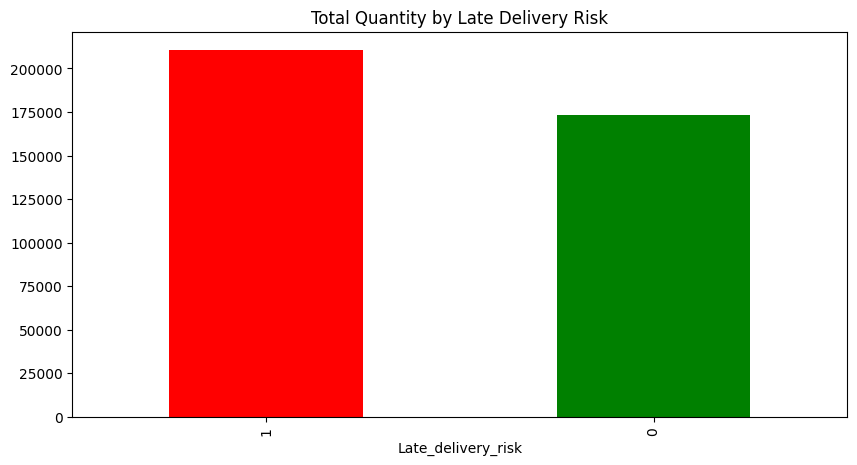

In [73]:
plt.title('Total Quantity by Late Delivery Risk')
df_data.groupby('Late_delivery_risk')['Order Item Quantity'].sum().sort_values(ascending = False).plot(kind = 'bar', figsize = (10,5), color = ['red','green'])


Insignt : We can see the bar graph that we have large amount of quantity ( 2Lakh + ) have a Late Delivery Risk 
Recommendation : We can focus on delivery time and be make sure to deliver product on time 

Text(0.5, 1.0, 'Late Delivery Risk by Shipping Segment')

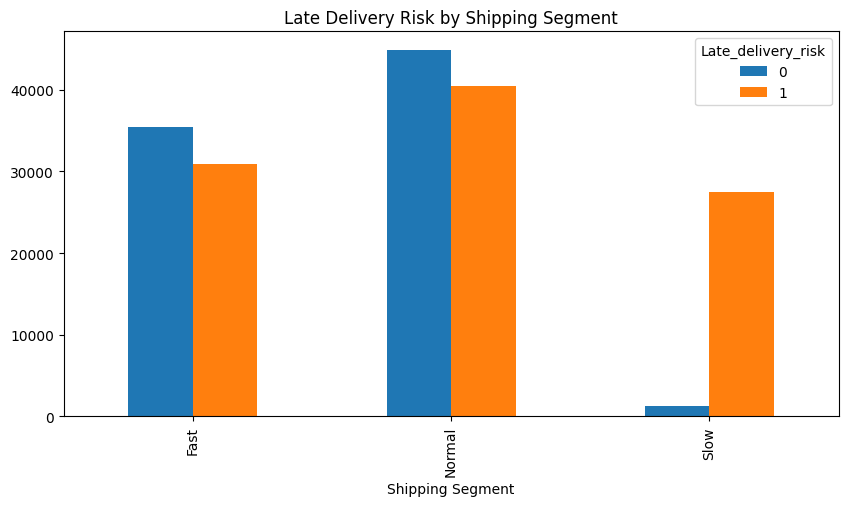

In [82]:
# Late Delivery Risk by Shipping Segment

bar_plot = df_data.groupby('Shipping Segment')['Late_delivery_risk'].value_counts().unstack().plot(kind = 'bar', figsize = (10,5))
bar_plot.set_title('Late Delivery Risk by Shipping Segment')

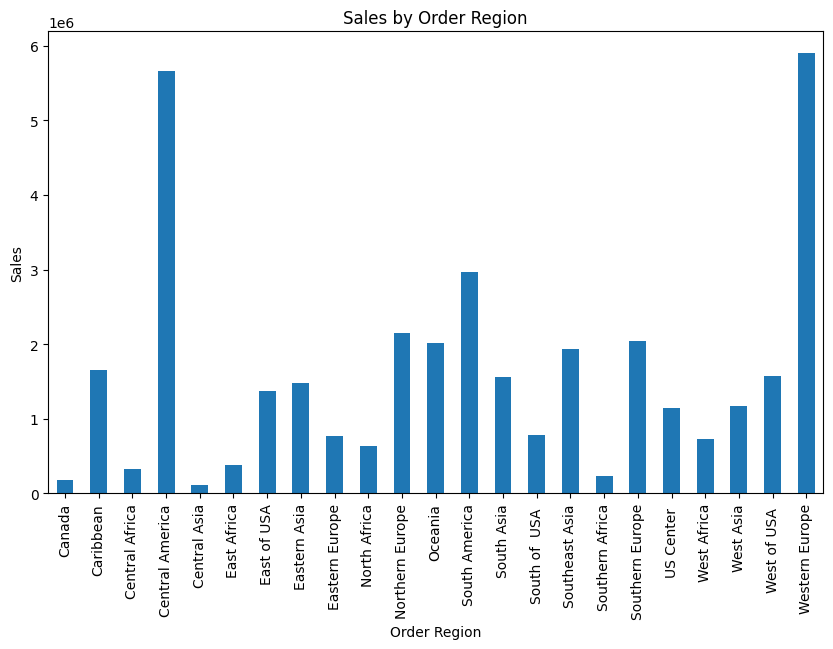

In [88]:
df_data.groupby('Order Region')['Sales'].sum().plot(kind = 'bar', figsize=(10,6))
plt.title('Sales by Order Region')
plt.xlabel('Order Region')
plt.ylabel('Sales')
plt.show()

In [89]:
# save  the csv file
df_data.to_csv('cleaned_supply_chain_data.csv', index=False)